In [32]:
import os
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
!ls models

In [33]:
from getpass import getpass
token = getpass("Paste GitHub token: ")

!git config --global user.email "your_email@gmail.com"
!git config --global user.name "Pooja Gosavi"
!echo "__pycache__/" > .gitignore
!git add .
!git commit -m "Add trained model and charts"
!git push https://{token}@github.com/pooja4730/churn-retention-strategy.git main

Paste GitHub token: ··········
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date


In [34]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("/content/telco.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [35]:
df.info()
df["Churn"].value_counts(normalize=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,proportion
Churn,
No,0.73463
Yes,0.26537


In [36]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

0 missing values
0 duplicate rows


In [39]:
import sys
import os
sys.path.append("..")
from src.features import add_features

df = add_features(df)

os.makedirs("../data", exist_ok=True)
df.to_csv("../data/clean.csv", index=False)
print("Features successfully added and saved to '../data/clean.csv'!")

Features successfully added and saved to '../data/clean.csv'!


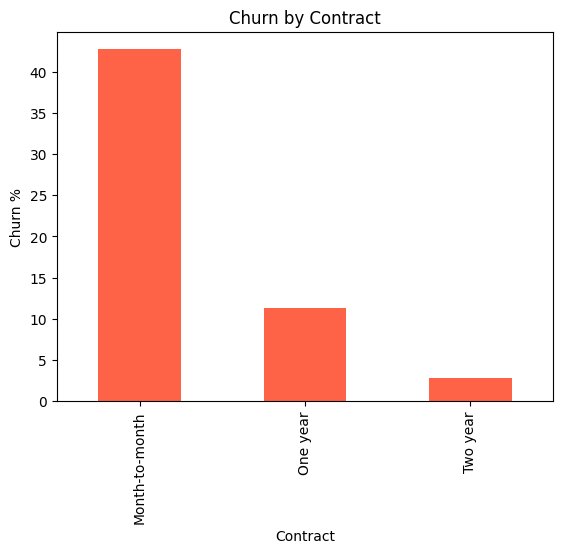

In [40]:
df.groupby("Contract")["Churn"].mean().mul(100).plot(kind="bar", color="tomato")
plt.ylabel("Churn %"); plt.title("Churn by Contract"); plt.show()

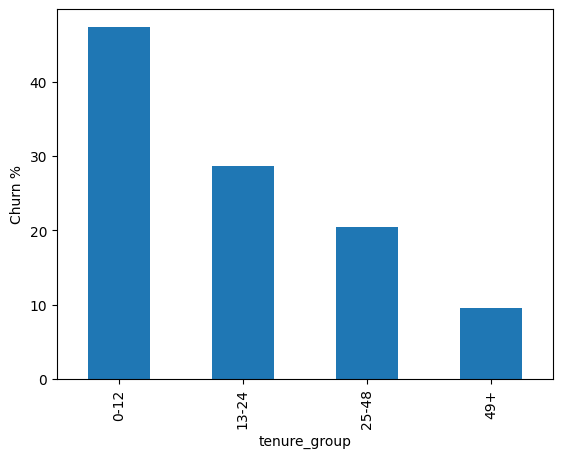

In [41]:
order = ["0-12", "13-24", "25-48", "49+"]
df.groupby("tenure_group")["Churn"].mean().reindex(order).mul(100).plot(kind="bar")
plt.ylabel("Churn %"); plt.show()

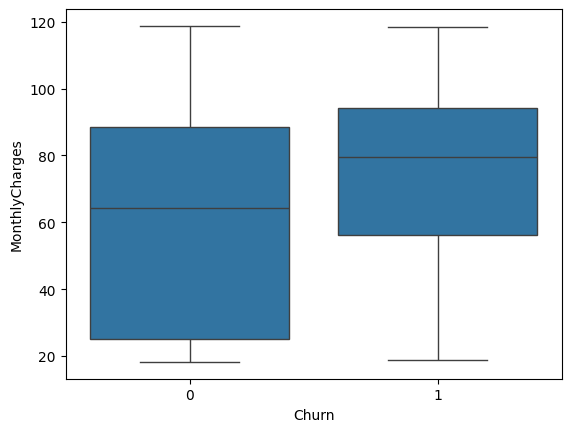

In [44]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.show()

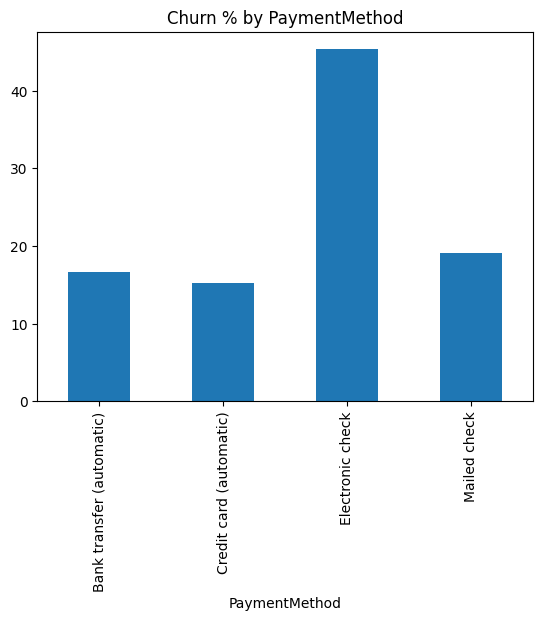

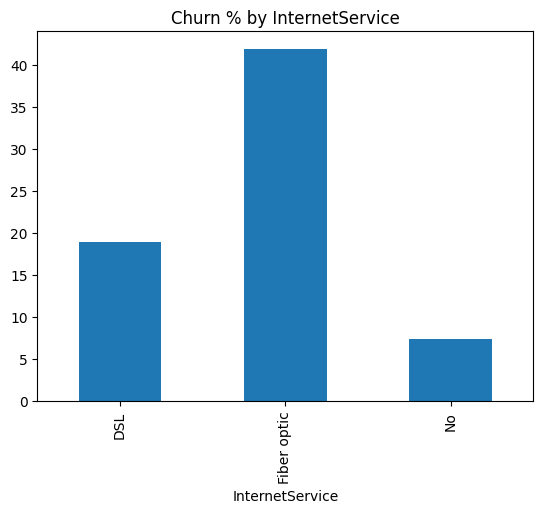

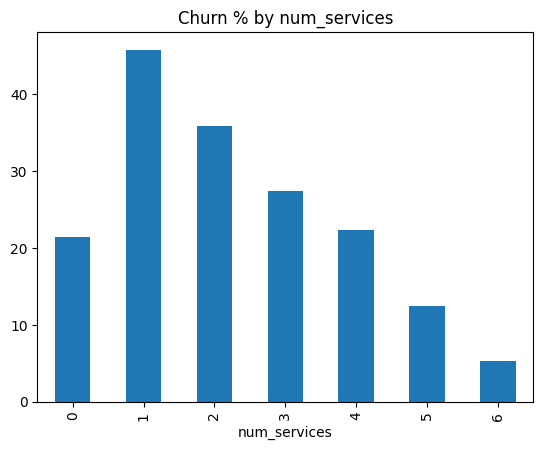

In [45]:
for col in ["PaymentMethod", "InternetService", "num_services"]:
    df.groupby(col)["Churn"].mean().mul(100).plot(kind="bar")
    plt.title(f"Churn % by {col}"); plt.show()

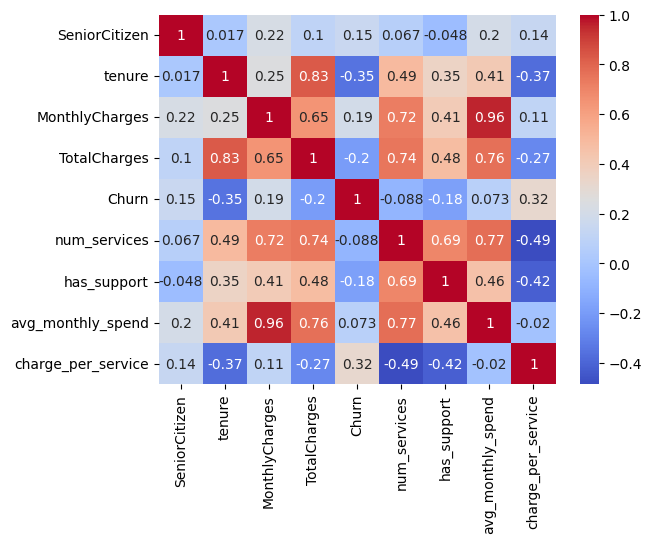

In [46]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.show()

In [47]:
import sqlite3
conn = sqlite3.connect("../data/churn.db")
df.to_sql("customers", conn, if_exists="replace", index=False)

q = """
SELECT Contract, COUNT(*) AS customers,
       ROUND(100.0 * SUM(Churn) / COUNT(*), 1) AS churn_pct
FROM customers GROUP BY Contract ORDER BY churn_pct DESC;
"""
pd.read_sql(q, conn)

,Contract,customers,churn_pct
0,Month-to-month,3875,42.7
1,One year,1473,11.3
2,Two year,1695,2.8


In [48]:
# Query 1: Churn by tenure group
q1 = """
SELECT tenure_group, ROUND(100.0*SUM(Churn)/COUNT(*),1) AS churn_pct
FROM customers GROUP BY tenure_group;
"""
print("--- Churn by Tenure Group ---")
display(pd.read_sql(q1, conn))

# Query 2: Churn by payment method
q2 = """
SELECT PaymentMethod, ROUND(100.0*SUM(Churn)/COUNT(*),1) AS churn_pct
FROM customers GROUP BY PaymentMethod ORDER BY churn_pct DESC;
"""
print("\n--- Churn by Payment Method ---")
display(pd.read_sql(q2, conn))

# Query 3: Churn by internet service
q3 = """
SELECT InternetService, ROUND(100.0*SUM(Churn)/COUNT(*),1) AS churn_pct
FROM customers GROUP BY InternetService;
"""
print("\n--- Churn by Internet Service ---")
display(pd.read_sql(q3, conn))

# Query 4: Revenue lost to churners
q4 = """
SELECT ROUND(SUM(MonthlyCharges),0) AS monthly_revenue_lost
FROM customers WHERE Churn = 1;
"""
print("\n--- Revenue Lost to Churners ---")
display(pd.read_sql(q4, conn))

# Query 5: Churn by tech support
q5 = """
SELECT TechSupport, ROUND(100.0*SUM(Churn)/COUNT(*),1) AS churn_pct
FROM customers GROUP BY TechSupport;
"""
print("\n--- Churn by Tech Support ---")
display(pd.read_sql(q5, conn))

--- Churn by Tenure Group ---


,tenure_group,churn_pct
0,0-12,47.4
1,13-24,28.7
2,25-48,20.4
3,49+,9.5



--- Churn by Payment Method ---


,PaymentMethod,churn_pct
0,Electronic check,45.3
1,Mailed check,19.1
2,Bank transfer (automatic),16.7
3,Credit card (automatic),15.2



--- Churn by Internet Service ---


,InternetService,churn_pct
0,DSL,19.0
1,Fiber optic,41.9
2,No,7.4



--- Revenue Lost to Churners ---


,monthly_revenue_lost
0,139131.0



--- Churn by Tech Support ---


,TechSupport,churn_pct
0,No,41.6
1,No internet service,7.4
2,Yes,15.2


In [49]:
!git clone https://github.com/pooja4730/churn-retention-strategy.git
%cd churn-retention-strategy
!pip install -q shap xgboost

import os
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
!ls data src

Cloning into 'churn-retention-strategy'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 28 (delta 5), reused 4 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 170.38 KiB | 1.69 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/churn-retention-strategy/churn-retention-strategy/churn-retention-strategy/churn-retention-strategy
data:

src:
features.py  __init__.py


In [56]:
import os
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

os.makedirs("models", exist_ok=True)
model_path = "models/best_model.joblib"

exclude_cols = ["customerID", "Churn", "churn_prob", "risk_tier"]
feature_cols = [col for col in df.columns if col not in exclude_cols]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df["Churn"]

if not os.path.exists(model_path):
    print("Model file not found. Training a new XGBoost model...")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = XGBClassifier(random_state=42, eval_metric="logloss")
    model.fit(X_train, y_train)
    joblib.dump(model, model_path)
    print(f"Successfully trained and saved model to {model_path}")
try:
    best = joblib.load(model_path)
    print(f"Successfully loaded model from {model_path}")
except Exception as e:
    print("Could not load the saved model file.")
    raise e
model_features = getattr(best, "feature_names_in_", None)
if model_features is not None:
    for col in model_features:
        if col not in X.columns:
            X[col] = 0
    X = X[model_features]

df["churn_prob"] = best.predict_proba(X)[:, 1]
df["risk_tier"] = pd.cut(df["churn_prob"], bins=[-0.01, 0.3, 0.6, 1.0], labels=["Low", "Medium", "High"])
print("\n--- Risk Tier Distribution ---")
print(df["risk_tier"].value_counts())

os.makedirs("data", exist_ok=True)
df.to_csv("data/customers_scored.csv", index=False)
print("\nSuccessfully saved scored dataset to 'data/customers_scored.csv'")

Successfully loaded model from models/best_model.joblib

--- Risk Tier Distribution ---
risk_tier
Low       4642
High      1386
Medium    1015
Name: count, dtype: int64

Successfully saved scored dataset to 'data/customers_scored.csv'


In [57]:
import sklearn, xgboost, shap, pandas, numpy
reqs = f"""pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
shap=={shap.__version__}
streamlit
joblib
"""
open("requirements.txt", "w").write(reqs)
print(reqs)

pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.54.1
streamlit
joblib



In [58]:
from getpass import getpass
token = getpass("Paste GitHub token: ")

!git config --global user.email "poojagosavi473@gmail.com"
!git config --global user.name "Pooja Gosavi"
!echo "__pycache__/" > .gitignore
!git add .
!git status
!git commit -m "Add trained model, scored data and requirements"
!git push https://{token}@github.com/pooja4730/churn-retention-strategy.git main

Paste GitHub token: ··········
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   data/customers_scored.csv
	new file:   models/best_model.joblib
	new file:   requirements.txt

[main 1ecc48c] Add trained model, scored data and requirements
 3 files changed, 7051 insertions(+)
 create mode 100644 data/customers_scored.csv
 create mode 100644 models/best_model.joblib
 create mode 100644 requirements.txt
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (7/7), 383.77 KiB | 5.90 MiB/s, done.
Total 7 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: This repository moved. Please use the new location:
remote:   https://github.com/pooja4730/Churn-Retention-Strategy.git
To https://github.com/pooja4730/churn-r